# Figure 5: Research-area enrichment

Inspect the weighted 2021-2025 title and abstract corpus, then reconstruct the enrichment ratios and pointwise bootstrap intervals used in Figure 5. The caption reports a 1.5-fold threshold and omits plant biology after its validation check. See `MANUSCRIPT/01_MAIN.md`, Results, Mentions of analysis software grew faster than the microscopy literature, Figure 5 caption, and Methods, Research areas.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import domains as dm
from census.figures import fig5_domains as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

The registry fixes the aliases and shared microscopy context. `build_boolean_query()` shows the alias and context clauses; package-year queries add the publication year. The analysis uses the registry's aggregate packages without microscope-control programs.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'napari']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
4,qupath,QuPath,"""QuPath"" AND ((microscopy OR microscope) AND H..."


In [3]:
sample = inspect_processed('random_sample_2021_2025.csv.gz', ['tool_id', 'year', 'epmc_id', 'population', 'n_sampled', 'venue'])
stored = inspect_processed('domain_enrichment.csv')
d = dm.load_corpus()
print(f'Analysis corpus: {d.shape}; distinct paper identifiers: {d.epmc_id.nunique():,}')
display(d[['tool_id', 'year', 'population', 'n_sampled', 'w']].head())

random_sample_2021_2025.csv.gz: shape=(59929, 8)


,tool_id,year,epmc_id,population,n_sampled,venue
0,jupyter,2021,PPR425566,232,232,NaN
1,jupyter,2021,PPR373017,232,232,NaN
2,jupyter,2021,PPR363724,232,232,NaN
3,jupyter,2021,PPR294591,232,232,NaN
4,jupyter,2021,35127826,232,232,Frontiers in molecular biosciences


domain_enrichment.csv: shape=(266, 8)


,tool_id,domain,share,baseline,ratio,lo,hi,n
0,imagej,Neuroscience,22.697763,27.290095,0.831722,0.788867,0.879496,5000
1,imagej,Cancer,22.648838,21.457876,1.055502,0.997437,1.117119,5000
2,imagej,Immunology,28.072037,27.128756,1.034771,0.985883,1.086533,5000
3,imagej,Microbiology and infection,19.484658,19.595131,0.994362,0.936609,1.050844,5000
4,imagej,Development and organoids,11.519739,17.235937,0.668356,0.616476,0.721093,5000


Analysis corpus: (38487, 24); distinct paper identifiers: 33,229


,tool_id,year,population,n_sampled,w
0,imagej,2021,36121,1000,36.121
1,imagej,2021,36121,1000,36.121
2,imagej,2021,36121,1000,36.121
3,imagej,2021,36121,1000,36.121
4,imagej,2021,36121,1000,36.121


## Ratios, bootstrap intervals, and display rule

Each record receives weight `population / n_sampled`. For a package and area, the ratio is its weighted keyword share divided by the leave-one-package-out share among other analysis-package records. The saved `lo` and `hi` columns are the 2.5th and 97.5th percentiles from 500 bootstrap resamples within package-year strata. The colour rule requires a ratio of at least 1.5 or at most 1/1.5 and an interval that excludes 1.


In [4]:
enrichment = stored.copy()
enrichment['ratio_recalculated'] = enrichment.share / enrichment.baseline
enrichment['enriched'] = (enrichment.ratio >= 1.5) & (enrichment.lo > 1)
enrichment['depleted'] = (enrichment.ratio <= 1 / 1.5) & (enrichment.hi < 1)
assert np.allclose(enrichment.ratio, enrichment.ratio_recalculated, rtol=1e-10, atol=1e-12, equal_nan=True)
examples = enrichment.loc[
    ((enrichment.tool_id.eq('qupath')) & enrichment.domain.eq('Clinical and pathology')) |
    ((enrichment.tool_id.eq('napari')) & enrichment.domain.eq('Electron microscopy')) |
    ((enrichment.tool_id.eq('cellprofiler')) & enrichment.domain.eq('Computational methods')),
    ['tool_id', 'domain', 'share', 'baseline', 'ratio', 'lo', 'hi', 'enriched', 'depleted', 'n']
]
display(examples)
print(f'Stored contrasts: {enrichment.shape[0]}; display-rule hits: {int((enrichment.enriched | enrichment.depleted).sum())}.')
print('Intervals are pointwise and have no multiple-comparison adjustment.')

,tool_id,domain,share,baseline,ratio,lo,hi,enriched,depleted,n
35,qupath,Clinical and pathology,51.805133,27.454959,1.886913,1.817878,1.954979,True,False,4598
55,cellprofiler,Computational methods,15.481464,5.224622,2.963174,2.734066,3.214660,True,False,4289
207,napari,Electron microscopy,11.963190,5.064729,2.362059,2.131658,2.603328,True,False,652


Stored contrasts: 266; display-rule hits: 138.
Intervals are pointwise and have no multiple-comparison adjustment.


## Optional cached-only enrichment rebuild

Set `REBUILD` to `True` to call `domains.build_enrichment()` with the committed random sample and the fixed 500-resample seed. The output goes to a temporary CSV for comparison. This builder reads processed records only, makes no network requests, and does not overwrite `domain_enrichment.csv`.


In [5]:
REBUILD = False
if REBUILD:
    with TemporaryDirectory(prefix='figure4-enrichment-') as output_dir:
        rebuilt_path = Path(output_dir) / 'domain_enrichment.csv'
        rebuilt = dm.build_enrichment(out_path=rebuilt_path, n_boot=500, seed=1)
        pd.testing.assert_frame_equal(rebuilt, fs.load('domain_enrichment.csv'))
        print(f'Rebuilt {rebuilt.shape[0]} rows in a temporary CSV; stored values match.')

## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote Figure5__domains.png/.pdf/.svg


wrote Figure5__domains.png/.pdf/.svg
PNG shape: (1414, 2005, 4); mean absolute pixel difference: 0.000000


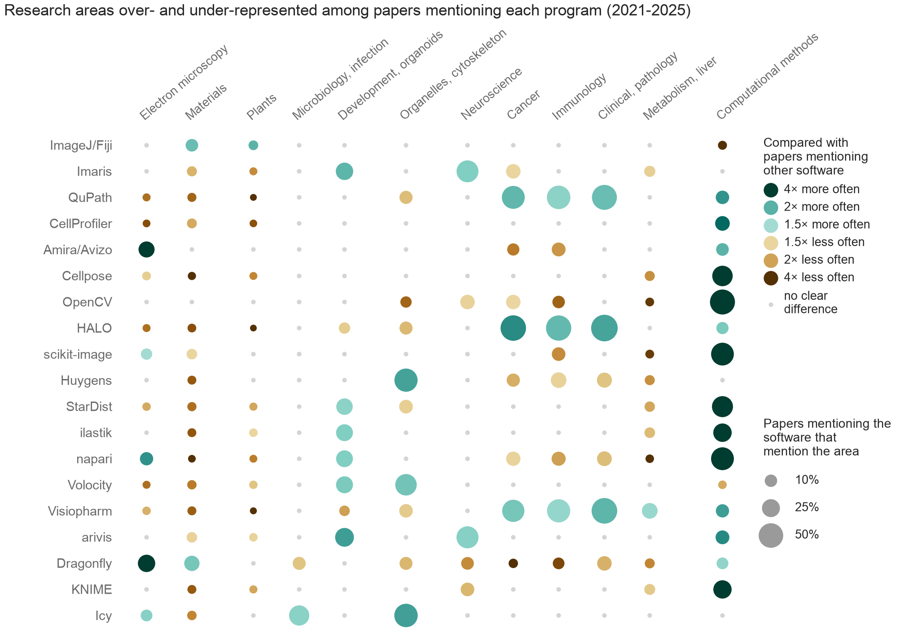

In [6]:
OUTPUT_STEM = 'Figure5__domains'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure4-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure4-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')